In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.base import clone

import warnings
warnings.filterwarnings("ignore")

In [4]:
!git clone -b megha-work https://github.com/meghagangal362015/cmpe257-early-reading-prediction.git

Cloning into 'cmpe257-early-reading-prediction'...
remote: Enumerating objects: 139, done.
remote: Counting objects: 100% (139/139), done.
remote: Compressing objects: 100% (111/111), done.
remote: Total 139 (delta 53), reused 91 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (139/139), 1.53 MiB | 13.06 MiB/s, done.
Resolving deltas: 100% (53/53), done.


In [5]:
%cd /content/cmpe257-early-reading-prediction

/content/cmpe257-early-reading-prediction


In [6]:
!ls data/processed

ecri_combined.csv	README.md  train.csv
paper_complete_706.csv	test.csv   validation.csv


In [7]:
paper_df = pd.read_csv("data/processed/paper_complete_706.csv")

print("Dataset shape:", paper_df.shape)
display(paper_df.head())

Dataset shape: (706, 19)


,SchlID,NWFcls,NWFwrc,ORFwc,SAwrS,SAsrS,SAtoS,RMwidRS,RMwdaRS,Gender,Tx,Age1b,Tier2_N,TKPctCrct,grp_rate,rcmistot,gnrl_fid,RMwidRS_target,RMwdaRS_target
0,1.0,31.0,8.0,8.0,424.0,441.0,459.0,12.0,4.0,1.0,1,85.0,13.0,84.848485,2.301621,3.699074,0.916667,1.0,1.0
1,1.0,40.0,13.0,9.0,419.0,457.0,472.0,17.0,6.0,1.0,1,76.0,13.0,84.848485,2.301621,3.699074,0.916667,1.0,1.0
2,1.0,14.0,4.0,8.0,419.0,435.0,450.0,9.0,2.0,1.0,1,75.0,13.0,84.848485,2.301621,3.699074,0.916667,1.0,0.0
3,1.0,32.0,11.0,8.0,419.0,462.0,468.0,18.0,7.0,1.0,1,80.0,13.0,84.848485,2.301621,3.699074,0.916667,1.0,1.0
4,1.0,39.0,13.0,13.0,429.0,419.0,457.0,17.0,8.0,0.0,1,73.0,13.0,84.848485,2.301621,3.699074,0.916667,1.0,1.0


In [8]:
paper_features = [
    "NWFcls",
    "NWFwrc",
    "ORFwc",
    "SAwrS",
    "SAsrS",
    "SAtoS",
    "RMwidRS",
    "RMwdaRS",
    "Gender",
    "Tx",
    "Age1b",
    "Tier2_N",
    "TKPctCrct",
    "grp_rate",
    "rcmistot",
    "gnrl_fid"
]

targets = {
    "Word Identification": "RMwidRS_target",
    "Word Attack": "RMwdaRS_target"
}

X = paper_df[paper_features].copy()
groups = paper_df["SchlID"]

print("Features:", X.shape)
print("Number of schools:", groups.nunique())
print("Targets:", targets)

Features: (706, 16)
Number of schools: 42
Targets: {'Word Identification': 'RMwidRS_target', 'Word Attack': 'RMwdaRS_target'}


In [9]:
group_kfold = GroupKFold(n_splits=5)

nb_results = []

for target_name, target_column in targets.items():

    y = paper_df[target_column].astype(int)

    fold_accuracies = []
    fold_pr_aucs = []

    for fold, (train_index, validation_index) in enumerate(
        group_kfold.split(X, y, groups=groups),
        start=1
    ):

        X_train = X.iloc[train_index]
        X_validation = X.iloc[validation_index]

        y_train = y.iloc[train_index]
        y_validation = y.iloc[validation_index]

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", GaussianNB())
        ])

        model.fit(X_train, y_train)

        predictions = model.predict(X_validation)
        probabilities = model.predict_proba(X_validation)[:, 1]

        accuracy = accuracy_score(y_validation, predictions)
        pr_auc = average_precision_score(
            y_validation,
            probabilities
        )

        fold_accuracies.append(accuracy)
        fold_pr_aucs.append(pr_auc)

        nb_results.append({
            "Target": target_name,
            "Fold": fold,
            "Accuracy": accuracy,
            "PR-AUC": pr_auc
        })

nb_results_df = pd.DataFrame(nb_results)

display(nb_results_df.round(4))

,Target,Fold,Accuracy,PR-AUC
0,Word Identification,1,0.5915,0.5841
1,Word Identification,2,0.6408,0.5740
2,Word Identification,3,0.6643,0.8265
3,Word Identification,4,0.5786,0.6136
4,Word Identification,5,0.6620,0.6189
5,Word Attack,1,0.5845,0.6638
6,Word Attack,2,0.6408,0.7012
7,Word Attack,3,0.6143,0.7387
8,Word Attack,4,0.4929,0.5252
9,Word Attack,5,0.6338,0.7011


In [10]:
nb_summary = (
    nb_results_df
    .groupby("Target")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        Mean_PR_AUC=("PR-AUC", "mean"),
        PR_AUC_SD=("PR-AUC", "std")
    )
    .reset_index()
)

display(nb_summary.round(4))

,Target,Mean_Accuracy,Accuracy_SD,Mean_PR_AUC,PR_AUC_SD
0,Word Attack,0.5933,0.0602,0.6660,0.0830
1,Word Identification,0.6274,0.0400,0.6434,0.1041


In [11]:
comparison_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "Naive Bayes"
    ],
    "Word Identification PR-AUC": [
        0.6920,
        0.6835,
        0.6434
    ],
    "Word Attack PR-AUC": [
        0.6686,
        0.6786,
        0.6660
    ]
})

display(comparison_results.round(4))

,Model,Word Identification PR-AUC,Word Attack PR-AUC
0,Random Forest,0.6920,0.6686
1,XGBoost,0.6835,0.6786
2,Naive Bayes,0.6434,0.6660


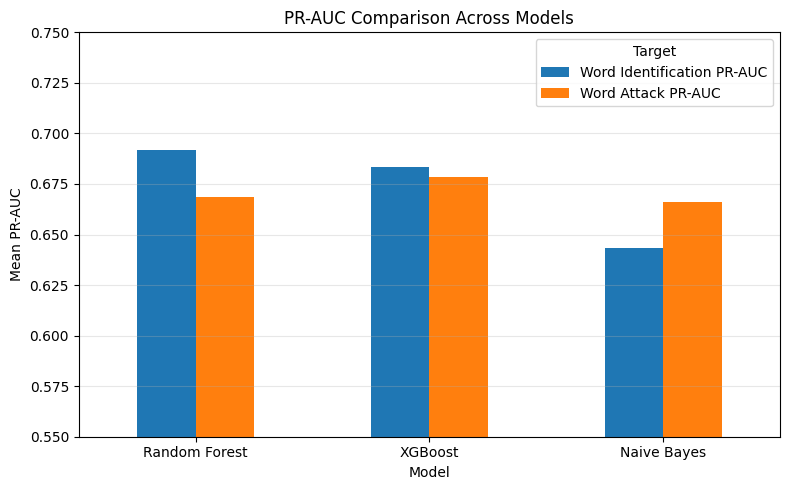

In [12]:
import matplotlib.pyplot as plt

comparison_plot = comparison_results.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("PR-AUC Comparison Across Models")
plt.ylabel("Mean PR-AUC")
plt.xlabel("Model")
plt.ylim(0.55, 0.75)
plt.xticks(rotation=0)
plt.legend(title="Target")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
import os

os.makedirs("results", exist_ok=True)

nb_results_df.to_csv(
    "results/naive_bayes_cv_results.csv",
    index=False
)

nb_summary.to_csv(
    "results/naive_bayes_summary.csv",
    index=False
)

comparison_results.to_csv(
    "results/model_comparison_with_naive_bayes.csv",
    index=False
)

print("Naive Bayes results saved successfully.")

Naive Bayes results saved successfully.


In [14]:
!ls results
!git status

feature_group_ablation_results.csv
model_comparison_with_naive_bayes.csv
naive_bayes_cv_results.csv
naive_bayes_summary.csv
random_forest_cv_fold_results.csv
random_forest_cv_summary.csv
random_forest_feature_importance.csv
random_forest_tuning_results.csv
random_forest_vs_xgboost_comparison.csv
random_forest_vs_xgboost_mean_results.csv
tuned_model_comparison.csv
xgboost_cv_fold_results.csv
xgboost_cv_summary.csv
xgboost_tuning_results.csv
On branch megha-work
Your branch is up to date with 'origin/megha-work'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	results/model_comparison_with_naive_bayes.csv
	results/naive_bayes_cv_results.csv
	results/naive_bayes_summary.csv

nothing added to commit but untracked files present (use "git add" to track)
